# 19 · An agent as a service: its card says what it can do
Level L4 · Part 4 · core · ~25 min · builds on 11, 12

## Goal
Treat an agent as a service that other code can use. Every agent gets a **card**: a short, structured description of its name, what it
does, what it accepts, what it needs to call it, and the skills it offers. The card is built from the agent's own tools, so it cannot drift
from what the agent really does. Then the card is used to call the agent.

## Why it matters
An agent that other teams call is an API with no documentation unless you write one. A caller that guesses the input, or assumes a skill the
agent does not have, fails in production. A card is the contract: it says what the agent will do, and what it will refuse.

| An agent with no card | An agent with a card |
|---|---|
| The caller reads the code to learn what it does | The caller reads the card |
| A skill is described in a sentence nobody checks | Each skill is listed with its input |
| The description and the tools drift apart | The card is generated from the tools |

**What it makes easy:** finding an agent and using it without a meeting. **When you don't need it:** an agent used only inside one program.

## The idea
An **agent card** has a name, a description, the **skills** (each with its input and what it returns), the **input and output
modes** (text, JSON), the things the agent **refuses**, and the **auth** needed to call it. The agent itself is the graph from lesson 11. The
card is data that describes the graph, and a caller reads only the card.

## Picture
The card is generated from the agent, and a caller uses the card to send a request.

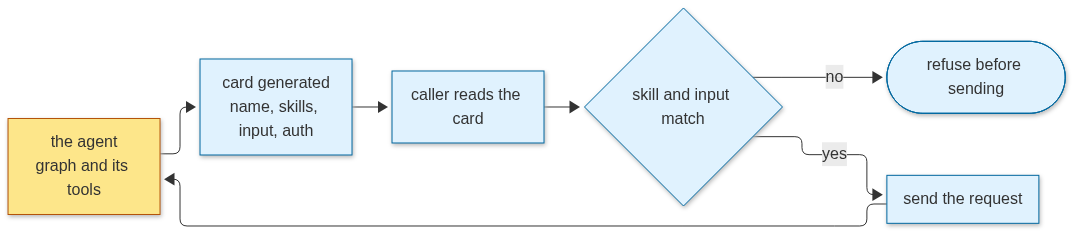

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid  # course helper: draws a Mermaid diagram inside the notebook

show_mermaid("""
flowchart LR
  A["the agent<br/>graph and its tools"] --> C["card generated<br/>name, skills, input, auth"]
  C --> K["caller reads the card"]
  K --> Q{"skill and input match"}
  Q -->|yes| R["send the request"] --> A
  Q -->|no| X(["refuse before sending"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class A model
  class C,K,Q,R,X code
""")

## Step by step
**Step 1 · the agent's tools (no call).** Two tools with schemas. Each tool's name, description and argument schema are what the card will
list, so the card is a view of the tools, not a second copy.

In [2]:
import json
from pathlib import Path

from langchain_core.tools import tool
from pydantic import BaseModel, ConfigDict, Field

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})


@tool
def policy_summary(topic: str) -> str:
    """Summarise the desk's policy on one topic: refunds, returns or delivery."""
    return f"Policy on {topic}: refunds need a person's approval; returns within 30 days of delivery."


TOOLS = [lookup_order, policy_summary]
print([t.name for t in TOOLS])

['lookup_order', 'policy_summary']


**Step 2 · the card, generated from the tools (no call).** `make_card` reads each tool's name, description and schema, and writes the skills.
It also states what the agent refuses, which a caller needs to know before sending a request.

In [3]:
class Skill(BaseModel):
    id: str
    description: str
    input_schema: dict


class AgentCard(BaseModel):
    name: str
    description: str
    skills: list[Skill]
    input_modes: list[str] = ["text"]
    output_modes: list[str] = ["text"]
    refuses: list[str] = ["refund payments: a person approves them"]
    auth: str = "none for read-only skills"


def make_card(name: str, description: str, tools) -> AgentCard:
    skills = [Skill(id=t.name, description=t.description, input_schema=t.args_schema.model_json_schema()) for t in tools]
    return AgentCard(name=name, description=description, skills=skills)


CARD = make_card("brightside-desk", "Answers order and policy questions for Brightside Outfitters customers.", TOOLS)
print(CARD.model_dump_json(indent=2)[:700], "…")

{
  "name": "brightside-desk",
  "description": "Answers order and policy questions for Brightside Outfitters customers.",
  "skills": [
    {
      "id": "lookup_order",
      "description": "Look up one customer order: its status and days late.",
      "input_schema": {
        "additionalProperties": false,
        "properties": {
          "order_id": {
            "description": "The order number the customer wrote: four digits, such as 1003.",
            "pattern": "^\\d{4}$",
            "title": "Order Id",
            "type": "string"
          }
        },
        "required": [
          "order_id"
        ],
        "title": "OrderQuery",
        "type": "object"
      }
    },
  …


**Step 3 · the caller checks the card before it sends (no call).** A caller finds the skill it needs, and checks the input against the skill's
schema. A request that does not match is refused before it leaves the caller, so the agent never sees it.

In [4]:
import jsonschema


def check_request(card: AgentCard, skill_id: str, payload: dict) -> tuple[bool, str]:
    skill = next((s for s in card.skills if s.id == skill_id), None)
    if skill is None:
        return False, f"the agent has no skill {skill_id!r}; it has {[s.id for s in card.skills]}"
    try:
        jsonschema.validate(payload, skill.input_schema)
        return True, "matches the card"
    except jsonschema.ValidationError as error:
        return False, error.message


print(check_request(CARD, "lookup_order", {"order_id": "1003"}))
print(check_request(CARD, "lookup_order", {"order_id": "1003", "days": 9}))
print(check_request(CARD, "refund_order", {"order_id": "1003"}))

(True, 'matches the card')
(False, "Additional properties are not allowed ('days' was unexpected)")
(False, "the agent has no skill 'refund_order'; it has ['lookup_order', 'policy_summary']")


**Step 4 · the agent answers the matched request (1 model call).** The caller sends a request that matches the card. The agent is an ordinary
agent with the same tools: the model picks the skill, the tool runs, and the model answers.

In [5]:
import llm_replay  # course helper: records the model's answers once, so the lesson replays offline without a key
llm_replay.start("19_agent-as-a-service")

from langchain.agents import create_agent
from langchain_core.messages import HumanMessage
from llm_setup import get_llm  # course helper: the shared model setup (Gemini on Vertex AI)

agent = create_agent(model=get_llm(), tools=TOOLS,
                     system_prompt="You are the Brightside desk. Use a tool for order facts and policy.")
ok, why = check_request(CARD, "lookup_order", {"order_id": "1003"})
if ok:
    answer = agent.invoke({"messages": [HumanMessage(content="What is the status of order 1003?")]},
                          config={"recursion_limit": 6})
    print("answer:", answer["messages"][-1].text)
llm_replay.stop()  # the last model call of this lesson

LLM mode: replay (19_agent-as-a-service.yaml)


Gemini on Vertex AI · API key loaded: True
answer: Order 1003 is currently marked as lost and is 9 days late. I apologize for the inconvenience. Would you like me to look up our policy on how we handle lost orders?


## At work
- Teams publish a card for each agent that others call. The card is reviewed like an API contract, and changes to it are versioned →
  lesson 21 (agent registry).
- A card that lists a refund skill with no approval note is a risk. The `refuses` field makes the rule visible to every caller → lesson 34
  (security and guardrails).
- The card is what discovery reads. Lesson 20 shows how a caller finds it without a hard-coded address.

## What just happened
- The card lists two skills, `lookup_order` and `policy_summary`, and both were generated from the tools.
- The request with `order_id` `1003` matches the card: `(True, 'matches the card')`. Adding a `days` field is refused: "Additional properties are not allowed".
- A request for `refund_order` is refused because the card has no such skill.
- The matched request got an answer from the course model: order 1003 is lost and 9 days late, the same facts as the order data.

## Common mistakes
1. **A card written by hand.** A hand-written card drifts from the tools within a month. Here the card still names `lookup_orders`, a skill
   that was renamed. The caller's check refuses a request that the agent could have answered:

In [6]:
old_card = AgentCard(name="brightside-desk", description="Order desk.",
                     skills=[Skill(id="lookup_orders", description="Look up an order.", input_schema={"type": "object"})])
print(check_request(old_card, "lookup_order", {"order_id": "1003"}))

(False, "the agent has no skill 'lookup_order'; it has ['lookup_orders']")


2. **No refusals listed.** A caller learns what the agent refuses only from the `refuses` field. Read it before the first request, so the
   refund rule is not a surprise:

In [7]:
print(CARD.refuses)

['refund payments: a person approves them']


3. **Trusting the caller's input.** The caller checks the card, but the agent must check again on arrival. A request that skips the card still
   meets the tool's own schema, and the bad order number is rejected there:

In [8]:
try:
    lookup_order.invoke({"order_id": "12"})
except Exception as error:
    print(type(error).__name__, "|", " ".join(str(error).splitlines()[:3]))

ValidationError | 1 validation error for OrderQuery order_id   String should match pattern '^\d{4}$' [type=string_pattern_mismatch, input_value='12', input_type=str]


## Try it
Write `skill_ids(card)` that returns the list of skill ids in the card. Test it on `CARD`. No model call is needed.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
def skill_ids(card: AgentCard) -> list[str]:
    return [s.id for s in card.skills]


print(skill_ids(CARD))  # ['lookup_order', 'policy_summary']

['lookup_order', 'policy_summary']


## Key terms
- **Agent card** — a structured description of an agent: its name, skills, modes, refusals and auth.
- **Skill** — one thing the agent can do, with the input it accepts.
- **Input schema** — a JSON Schema that says which fields a request must have and what types they are.
- **Refuses** — the list of requests the agent will not handle, published so callers know in advance.
- **Auth** — what a caller must present to use the agent.

## Recap
- An agent is a service with a card. The card lists its skills, their inputs, what it refuses and its auth.
- The card is generated from the tools, so it matches what the agent does.
- A caller checks the request against the card before sending it.

**Interview:** "How does another team know what your agent can do, without reading its code?" Strong answer: "The agent publishes a card generated from its
tools: skills, input schemas, what it refuses and how to authenticate. The caller checks its request against the card before sending."